Raw dataset
      ↓
Define X and y
      ↓
Reserve final test data
      ↓
Create training and validation data
      ↓
Build preprocessing
      ↓
Establish a simple majority baseline
      ↓
Train SGD Classifier
      ↓
Train Decision Tree Classifier
      ↓
Evaluate on validation data
      ↓
Compare initial models

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [4]:
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

dataset_path = (
    project_root
    / "data"
    / "raw"
    / "manufacturing_6G_dataset.csv"
)

figures_dir = project_root / "figures"
figures_dir.mkdir(exist_ok=True)

df = pd.read_csv(dataset_path)

df["Timestamp"] = pd.to_datetime(
    df["Timestamp"]
)

print("Dataset shape:", df.shape)

Dataset shape: (100000, 13)


In [5]:
X = df.drop(
    columns=[
        "Efficiency_Status",
        "Timestamp",
        "Machine_ID"
    ]
)

y = df["Efficiency_Status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

X shape: (100000, 10)
y shape: (100000,)

Input columns:
['Operation_Mode', 'Temperature_C', 'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms', 'Packet_Loss_%', 'Quality_Control_Defect_Rate_%', 'Production_Speed_units_per_hr', 'Predictive_Maintenance_Score', 'Error_Rate_%']


In [6]:
print(y.value_counts())

print()

print(
    y.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Low       77825
Medium    19189
High       2986
Name: Efficiency_Status, dtype: int64

Low       77.82
Medium    19.19
High       2.99
Name: Efficiency_Status, dtype: float64


In [7]:
X_development, X_test, y_development, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print(
    "Development set:",
    X_development.shape
)

print(
    "Final test set:",
    X_test.shape
)

Development set: (80000, 10)
Final test set: (20000, 10)


In [8]:
def class_distribution(labels):

    return (
        labels
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )


distribution_comparison = pd.DataFrame({
    "Original": class_distribution(y),
    "Development": class_distribution(
        y_development
    ),
    "Test": class_distribution(y_test)
})

distribution_comparison

,Original,Development,Test
Low,77.82,77.82,77.82
Medium,19.19,19.19,19.19
High,2.99,2.99,2.99


In [9]:
X_train, X_validation, y_train, y_validation = (
    train_test_split(
        X_development,
        y_development,
        test_size=0.20,
        random_state=42,
        stratify=y_development
    )
)

print(
    "Training set:",
    X_train.shape
)

print(
    "Validation set:",
    X_validation.shape
)

print(
    "Final test set:",
    X_test.shape
)

Training set: (64000, 10)
Validation set: (16000, 10)
Final test set: (20000, 10)


In [10]:
numerical_features = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Production_Speed_units_per_hr",
    "Predictive_Maintenance_Score",
    "Error_Rate_%"
]

categorical_features = [
    "Operation_Mode"
]

print(
    "Numerical features:",
    len(numerical_features)
)

print(
    "Categorical features:",
    len(categorical_features)
)

Numerical features: 9
Categorical features: 1


In [11]:
print(
    X_train["Operation_Mode"]
    .value_counts()
)

Active         44909
Idle           12807
Maintenance     6284
Name: Operation_Mode, dtype: int64


In [12]:
df[numerical_features].agg(
    ["min", "max"]
).T

,min,max
Temperature_C,30.000138,89.998979
Vibration_Hz,0.100011,4.999974
Power_Consumption_kW,1.500183,9.999889
Network_Latency_ms,1.000025,49.999917
Packet_Loss_%,0.000026,4.999975
Quality_Control_Defect_Rate_%,0.000449,9.999900
Production_Speed_units_per_hr,50.000375,499.996768
Predictive_Maintenance_Score,0.000003,0.999978
Error_Rate_%,0.000112,14.999869


In [13]:
sgd_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

sgd_preprocessor

ColumnTransformer(transformers=[('numerical', StandardScaler(),
                                 ['Temperature_C', 'Vibration_Hz',
                                  'Power_Consumption_kW', 'Network_Latency_ms',
                                  'Packet_Loss_%',
                                  'Quality_Control_Defect_Rate_%',
                                  'Production_Speed_units_per_hr',
                                  'Predictive_Maintenance_Score',
                                  'Error_Rate_%']),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Operation_Mode'])])

In [14]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

tree_preprocessor

ColumnTransformer(transformers=[('numerical', 'passthrough',
                                 ['Temperature_C', 'Vibration_Hz',
                                  'Power_Consumption_kW', 'Network_Latency_ms',
                                  'Packet_Loss_%',
                                  'Quality_Control_Defect_Rate_%',
                                  'Production_Speed_units_per_hr',
                                  'Predictive_Maintenance_Score',
                                  'Error_Rate_%']),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Operation_Mode'])])

In [19]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(
    X_train,
    y_train
)

dummy_predictions = dummy_model.predict(
    X_validation
)

dummy_accuracy = accuracy_score(
    y_validation,
    dummy_predictions
)

dummy_macro_f1 = f1_score(
    y_validation,
    dummy_predictions,
    average="macro"
)

print(
    "Dummy Accuracy:",
    round(dummy_accuracy, 4)
)

print(
    "Dummy Macro F1:",
    round(dummy_macro_f1, 4)
)
print("dummy_predictions:", dummy_predictions.shape[0])

Dummy Accuracy: 0.7782
Dummy Macro F1: 0.2918
dummy_predictions: 16000


In [20]:
sgd_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            sgd_preprocessor
        ),
        (
            "model",
            SGDClassifier(
                random_state=42,
                max_iter=2000
            )
        )
    ]
)

sgd_pipeline

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerical', StandardScaler(),
                                                  ['Temperature_C',
                                                   'Vibration_Hz',
                                                   'Power_Consumption_kW',
                                                   'Network_Latency_ms',
                                                   'Packet_Loss_%',
                                                   'Quality_Control_Defect_Rate_%',
                                                   'Production_Speed_units_per_hr',
                                                   'Predictive_Maintenance_Score',
                                                   'Error_Rate_%']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Operati

In [21]:
sgd_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerical', StandardScaler(),
                                                  ['Temperature_C',
                                                   'Vibration_Hz',
                                                   'Power_Consumption_kW',
                                                   'Network_Latency_ms',
                                                   'Packet_Loss_%',
                                                   'Quality_Control_Defect_Rate_%',
                                                   'Production_Speed_units_per_hr',
                                                   'Predictive_Maintenance_Score',
                                                   'Error_Rate_%']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Operati

In [23]:
sgd_predictions = sgd_pipeline.predict(
    X_validation
)

print(
    "First 10 predictions:"
)

print(
    sgd_predictions[:10]
)

print(
    "\nFirst 10 actual values:"
)

print(
    y_validation.iloc[:10].values
)

First 10 predictions:
['Low' 'Low' 'Medium' 'Low' 'Low' 'Low' 'Low' 'Low' 'Medium' 'Low']

First 10 actual values:
['Low' 'Low' 'Medium' 'Medium' 'Low' 'Low' 'Low' 'Low' 'Medium' 'Low']


In [24]:
def evaluate_model(
    model_name,
    y_true,
    y_pred
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    }

In [25]:
sgd_results = evaluate_model(
    "SGD Classifier",
    y_validation,
    sgd_predictions
)

pd.DataFrame(
    [sgd_results]
).round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,SGD Classifier,0.9038,0.8991,0.734,0.7918,0.9004


In [26]:
print(
    classification_report(
        y_validation,
        sgd_predictions,
        labels=[
            "Low",
            "Medium",
            "High"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       0.93      0.97      0.95     12452
      Medium       0.77      0.71      0.74      3070
        High       1.00      0.53      0.69       478

    accuracy                           0.90     16000
   macro avg       0.90      0.73      0.79     16000
weighted avg       0.90      0.90      0.90     16000



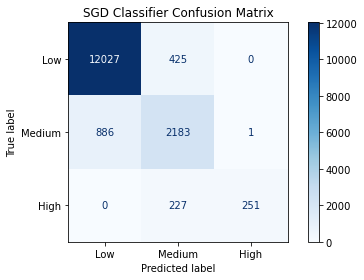

In [27]:
class_order = [
    "Low",
    "Medium",
    "High"
]

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    sgd_predictions,
    labels=class_order,
    cmap="Blues"
)

plt.title(
    "SGD Classifier Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "sgd_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()